# Alternative Macro Economic Indices API — Quickstart & Category Explorer

Explore real, sanitized macroeconomic leading indicators from the **Alternative Macro Economic Indices API (v1.2.0)** via RapidAPI (`https://alternative-macro-economic-indices.p.rapidapi.com`).

- **Tiers:** `BASIC` ($0 — `/v1/health`, `/v1/catalog`, limited `/v1/indices/{slug}`), `PRO` ($14.99 — category series, regime summary, strict `month` / `asOf` time filters), `ULTRA` ($39.99 — full history, `crisis-similarity`, `batch`). Restricted tiers return HTTP 200 with `previewMode: true`.
- **Zero Synthetic Data Policy:** Every observation is derived from official upstream series (FRED®, BLS, BEA, U.S. Census, EIA, DOT, SEC EDGAR, The Economist Big Mac CC BY 4.0, World Bank Pink Sheet CC BY 4.0) with strict non-fallback `month=YYYY-MM` behavior.
- **Links:** [RapidAPI Hub](https://rapidapi.com/stalter-stalter-default/api/alternative-macro-economic-indices) | [Live Web Dashboard](https://stalter.work/index) | [GitHub Repository](https://github.com/nkcDuck/altmacro-quant-api)

> **Colab & Offline Execution:** When `RAPIDAPI_KEY` is unset, this notebook automatically activates `DEMO_MODE` and reads the bundled real gateway captures under `examples/responses/`.


In [1]:
import json
import os
import sys
import subprocess
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

IN_COLAB = "google.colab" in sys.modules

def resolve_responses_dir() -> Path | None:
    candidates = [
        Path("examples/responses"),
        Path("../examples/responses"),
        Path("altmacro-quant-api/examples/responses"),
    ]
    for cand in candidates:
        if cand.is_dir() and (cand / "health.json").is_file():
            return cand.resolve()
    return None

RESPONSES_DIR = resolve_responses_dir()

if IN_COLAB and RESPONSES_DIR is None:
    repo_dir = Path("altmacro-quant-api")
    if not repo_dir.exists():
        subprocess.run(
            ["git", "clone", "--depth", "1", "https://github.com/nkcDuck/altmacro-quant-api.git"],
            check=True,
        )
    RESPONSES_DIR = resolve_responses_dir()

try:
    import requests
except ImportError:
    requests = None

RAPIDAPI_HOST = "alternative-macro-economic-indices.p.rapidapi.com"
BASE_URL = f"https://{RAPIDAPI_HOST}"

RAPIDAPI_KEY = os.environ.get("RAPIDAPI_KEY", "").strip()
if not RAPIDAPI_KEY and IN_COLAB:
    try:
        from google.colab import userdata  # type: ignore
        RAPIDAPI_KEY = (userdata.get("RAPIDAPI_KEY") or "").strip()
    except Exception:
        pass

ENV_DEMO = os.environ.get("DEMO_MODE", "").strip().lower() in {"1", "true", "yes"}
DEMO_MODE = ENV_DEMO or (not RAPIDAPI_KEY)

def api_get(endpoint_path: str, fallback_file: str, params: dict | None = None) -> dict:
    """Fetch from RapidAPI Proxy when RAPIDAPI_KEY is set, else load bundled offline sample."""
    if DEMO_MODE:
        if RESPONSES_DIR is None:
            raise FileNotFoundError("Could not locate examples/responses directory for DEMO_MODE.")
        payload = json.loads((RESPONSES_DIR / fallback_file).read_text(encoding="utf-8"))
    else:
        if requests is None:
            raise ImportError("requests is required for live RapidAPI calls.")
        headers = {
            "X-RapidAPI-Key": RAPIDAPI_KEY,
            "X-RapidAPI-Host": RAPIDAPI_HOST,
            "Accept": "application/json",
        }
        clean_params = {k: v for k, v in (params or {}).items() if v is not None}
        resp = requests.get(f"{BASE_URL}{endpoint_path}", headers=headers, params=clean_params, timeout=20)
        if resp.status_code == 429:
            retry_after = resp.headers.get("Retry-After", "unknown")
            raise RuntimeError(f"RapidAPI rate limit reached (HTTP 429, Retry-After={retry_after}).")
        resp.raise_for_status()
        payload = resp.json()

    if payload.get("previewMode"):
        print(f"[previewMode] {endpoint_path}: {payload.get('upgradeNotice', 'Upgrade tier for full history.')}")
    return payload

mode_str = "DEMO_MODE (offline examples/responses/)" if DEMO_MODE else "LIVE RapidAPI Proxy"
print(f"Runtime mode: {mode_str}")
print(f"Responses dir: {RESPONSES_DIR}")

Runtime mode: DEMO_MODE (offline examples/responses/)
Responses dir: C:\Users\kingk\.gemini\antigravity\scratch\teamwork_tmp\0131ffd4-f691-477c-b2b2-fcf03fb29e3b\altmacro-quant-api\examples\responses


## 1. Gateway Health & Manufacturing Catalog (`BASIC` Tier)


In [2]:
health = api_get("/v1/health", "health.json")
catalog = api_get("/v1/catalog", "catalog-manufacturing.json", params={"category": "manufacturing"})

h_data = health["data"]
print(
    f"Gateway status={h_data['status']} | service={h_data['service']} | "
    f"version={h_data['version']} | indicesTracked={h_data['indicesTracked']} | "
    f"tier={h_data.get('subscriptionTier')}"
)

cat_rows = []
for item in catalog["data"]["indices"]:
    sources = ", ".join(s.get("id", "") for s in item.get("upstreamSources", []))
    cat_rows.append({
        "slug": item["slug"],
        "name": item["name"],
        "dimension": item["dimension"],
        "licenseClass": item.get("licenseClass"),
        "redactedFieldCount": len(item.get("redactedRawFields", [])),
        "upstreamSourceIds": sources,
    })

df_catalog = pd.DataFrame(cat_rows)
df_catalog

Gateway status=ok | service=altIndicesApi | version=1.2.0 | indicesTracked=15 | tier=ULTRA


,slug,name,dimension,licenseClass,redactedFieldCount,upstreamSourceIds
0,cardboard,Cardboard Box Index,2,PUBLIC_DOMAIN_US_GOV,0,"FRED:IPN32221S, FRED:PCU322211322211"
1,heavy-truck,Heavy Truck & Freight Index,2,PUBLIC_DOMAIN_US_GOV,0,"FRED:HTRUCKSSAAR, FRED:TSIFRGHT, FRED:GASDESW"
2,electricity-pulse,Industrial Electricity Pulse Index,2,PUBLIC_DOMAIN_US_GOV,0,"FRED:IPG2211S, FRED:CAPUTLG2211S, FRED:IPMAN"
3,skyscraper,Skyscraper Capex Cycle Index,2,PUBLIC_DOMAIN_US_GOV,0,"FRED:TLCOMCONS, FRED:TTLCONS, FRED:DRCRELEXFACBS"


## 2. Single-Index Range Query: `/v1/indices/cardboard` (`BASIC` / `PRO`)


In [3]:
cb_range = api_get(
    "/v1/indices/cardboard",
    "index-cardboard-range.json",
    params={"fromMonth": "2025-01", "toMonth": "2026-11", "limit": 24},
)

print("timeFilter:", cb_range.get("timeFilter"))
print("pagination:", cb_range.get("pagination"))
print("previewMode:", cb_range.get("previewMode", False))

df_cardboard = pd.DataFrame(cb_range["data"]["history"]).sort_values("dataMonth").reset_index(drop=True)
cols = ["dataMonth", "indexValue", "zScore", "signal", "trend", "productionIndex", "productionYoY", "ppiCorrugated", "ppiYoY"]
df_cardboard[cols].tail(6)

timeFilter: {'mode': 'range', 'fromMonth': '2025-01', 'toMonth': '2026-11'}
pagination: {'returnedCount': 17, 'requestedLimit': 24, 'appliedLimit': 24, 'tierMaxLimit': 120, 'subscriptionTier': 'ULTRA'}
previewMode: False


,dataMonth,indexValue,zScore,signal,trend,productionIndex,productionYoY,ppiCorrugated,ppiYoY
11,2026-04,60.59,0.430191,Growth,stable,90.25,0.38,463.66,2.09
12,2026-05,59.70,0.392918,Growth,stable,89.28,-0.16,474.65,3.23
13,2026-06,77.58,1.241604,Expansion,up,90.11,0.55,481.44,4.38
14,2026-07,79.13,1.332558,Expansion,up,90.67,0.14,491.19,5.76
15,2026-08,45.36,-0.186235,Neutral,stable,88.20,-2.80,501.63,7.73
16,2026-09,51.49,0.059527,Neutral,stable,87.86,-2.95,506.27,8.89


## 3. Strict `month` vs Point-in-Time `asOf` Semantics (`PRO` Tier)


In [4]:
def query_cardboard_snapshot(month: str | None = None, as_of: str | None = None) -> dict:
    if not DEMO_MODE:
        params = {"month": month, "asOf": as_of}
        return api_get("/v1/indices/cardboard", "index-cardboard-range.json", params=params)
    history = cb_range["data"]["history"]
    if month is not None:
        matched = [r for r in history if r.get("dataMonth") == month][:1]
        tf = {"mode": "month", "month": month}
    elif as_of is not None:
        matched = [r for r in history if r.get("dataMonth", "") <= as_of][:1]
        tf = {"mode": "asOf", "asOf": as_of}
    else:
        matched = history[:1]
        tf = {"mode": "latest"}
    return {
        "data": {"slug": "cardboard", "latest": matched[0] if matched else None, "history": matched},
        "timeFilter": tf,
        "pagination": {"returnedCount": len(matched)},
    }

tests = [
    ("Strict month=2026-10 (unpublished)", query_cardboard_snapshot(month="2026-10")),
    ("Point-in-time asOf=2026-10", query_cardboard_snapshot(as_of="2026-10")),
    ("Strict month=2026-01 (trough)", query_cardboard_snapshot(month="2026-01")),
]

summary_rows = []
for label, res in tests:
    latest = res["data"]["latest"]
    summary_rows.append({
        "query": label,
        "mode": res["timeFilter"]["mode"],
        "returnedCount": res["pagination"]["returnedCount"],
        "dataMonth": latest.get("dataMonth") if latest else None,
        "indexValue": latest.get("indexValue") if latest else None,
        "signal": latest.get("signal") if latest else None,
    })

pd.DataFrame(summary_rows)

,query,mode,returnedCount,dataMonth,indexValue,signal
0,Strict month=2026-10 (unpublished),month,0,NaN,NaN,NaN
1,Point-in-time asOf=2026-10,asOf,1,2026-09,51.49,Neutral
2,Strict month=2026-01 (trough),month,1,2026-01,4.74,Deep Contraction


## 4. Category Time-Series Matrix: `/v1/categories/manufacturing` (`PRO` Tier)


In [5]:
cat_mfg = api_get(
    "/v1/categories/manufacturing",
    "category-manufacturing.json",
    params={"limit": 12},
)

long_rows = []
latest_rows = []
for slug, obs_list in cat_mfg["data"]["indices"].items():
    ordered = sorted(obs_list, key=lambda r: r["dataMonth"])
    for r in ordered:
        long_rows.append({
            "slug": slug,
            "dataMonth": r["dataMonth"],
            "indexValue": float(r["indexValue"]),
            "zScore": round(float(r["zScore"]), 4),
            "signal": r["signal"],
            "trend": r["trend"],
        })
    last = ordered[-1]
    latest_rows.append({
        "slug": slug,
        "latestMonth": last["dataMonth"],
        "indexValue": last["indexValue"],
        "zScore": round(float(last["zScore"]), 4),
        "signal": last["signal"],
        "trend": last["trend"],
    })

df_mfg_long = pd.DataFrame(long_rows)
df_mfg_pivot = df_mfg_long.pivot(index="dataMonth", columns="slug", values="indexValue").sort_index()
print(f"Long-form rows: {len(df_mfg_long)} | Staggered union months: {len(df_mfg_pivot)}")
print("\nLatest observation per manufacturing index (note staggered release months):")
display_latest = pd.DataFrame(latest_rows)
print(display_latest.to_string(index=False))
df_mfg_pivot

Long-form rows: 48 | Staggered union months: 13

Latest observation per manufacturing index (note staggered release months):
             slug latestMonth  indexValue  zScore          signal  trend
        cardboard     2026-09       51.49  0.0595         Neutral stable
      heavy-truck     2026-10       95.26  3.0000 Fleet Expansion     up
electricity-pulse     2026-10       47.32 -0.1072     Steady Load stable
       skyscraper     2026-09       67.49  0.7305 Commercial Boom     up


slug,cardboard,electricity-pulse,heavy-truck,skyscraper
dataMonth,,,,
2025-10,53.53,NaN,NaN,69.09
2025-11,27.39,47.41,13.51,63.00
2025-12,50.08,71.47,38.17,43.68
2026-01,4.74,24.46,32.40,59.77
2026-02,36.81,38.79,38.98,43.15
2026-03,85.33,49.42,31.35,47.50
2026-04,60.59,50.79,39.82,42.72
2026-05,59.70,45.24,61.35,60.71
2026-06,77.58,35.85,74.06,66.52


## 5. Inline Visualization: Cardboard Components & Manufacturing Trajectories


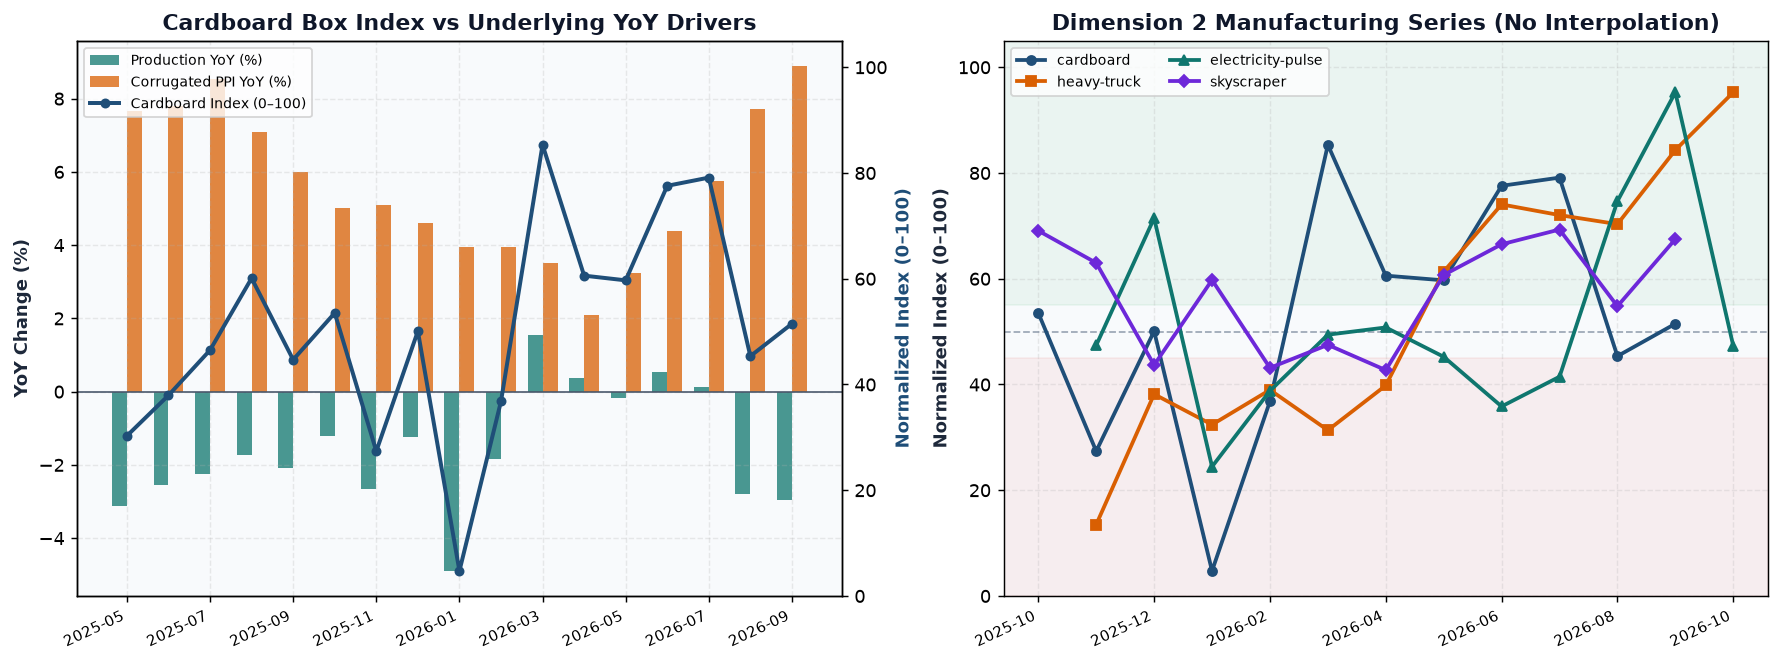

In [6]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(13.8, 5.2), dpi=130, facecolor="#ffffff")

# Left: Cardboard indexValue + productionYoY vs ppiYoY
ax1.set_facecolor("#f8fafc")
x_cb = range(len(df_cardboard))
w = 0.36
ax1.bar([i - w / 2 for i in x_cb], df_cardboard["productionYoY"], width=w, color="#0f766e", alpha=0.75, label="Production YoY (%)")
ax1.bar([i + w / 2 for i in x_cb], df_cardboard["ppiYoY"], width=w, color="#d95f02", alpha=0.75, label="Corrugated PPI YoY (%)")
ax1.axhline(0, color="#475569", lw=0.9)
ax1.set_xticks(list(x_cb)[::2])
ax1.set_xticklabels(df_cardboard["dataMonth"].iloc[::2], rotation=25, ha="right", fontsize=8.5)
ax1.set_ylabel("YoY Change (%)", fontweight="bold", color="#1e293b")
ax1.set_title("Cardboard Box Index vs Underlying YoY Drivers", fontweight="bold", color="#0f172a")
ax1.grid(True, linestyle="--", alpha=0.25)

ax1_r = ax1.twinx()
ax1_r.plot(list(x_cb), df_cardboard["indexValue"], color="#1f4e78", marker="o", lw=2.2, markersize=4.5, label="Cardboard Index (0–100)")
ax1_r.set_ylim(0, 105)
ax1_r.set_ylabel("Normalized Index (0–100)", fontweight="bold", color="#1f4e78")
h1, l1 = ax1.get_legend_handles_labels()
h2, l2 = ax1_r.get_legend_handles_labels()
ax1.legend(h1 + h2, l1 + l2, loc="upper left", fontsize=8, frameon=True, facecolor="#ffffff")

# Right: All 4 Manufacturing series (preserving NaNs / no interpolation)
ax2.set_facecolor("#f8fafc")
ax2.axhspan(55, 105, color="#16a34a", alpha=0.06)
ax2.axhspan(0, 45, color="#dc2626", alpha=0.06)
ax2.axhline(50, ls="--", lw=1.0, color="#64748b", alpha=0.6)

palette = {
    "cardboard": ("#1f4e78", "o"),
    "heavy-truck": ("#d95f02", "s"),
    "electricity-pulse": ("#0f766e", "^"),
    "skyscraper": ("#6d28d9", "D"),
}
months_union = list(df_mfg_pivot.index)
x_u = list(range(len(months_union)))
for slug, (col, mk) in palette.items():
    vals = df_mfg_pivot[slug]
    valid = vals.notna()
    ax2.plot([i for i, ok in zip(x_u, valid) if ok], vals[valid], color=col, marker=mk, lw=2.1, markersize=5, label=slug)

ax2.set_xticks(x_u[::2])
ax2.set_xticklabels([months_union[i] for i in x_u[::2]], rotation=25, ha="right", fontsize=8.5)
ax2.set_ylim(0, 105)
ax2.set_ylabel("Normalized Index (0–100)", fontweight="bold", color="#1e293b")
ax2.set_title("Dimension 2 Manufacturing Series (No Interpolation)", fontweight="bold", color="#0f172a")
ax2.grid(True, linestyle="--", alpha=0.25)
ax2.legend(loc="upper left", ncol=2, fontsize=8, frameon=True, facecolor="#ffffff")

plt.tight_layout()
plt.show()

## 6. Compliance & Licensing Attribution


In [7]:
meta = cat_mfg.get("meta", {})
print("License:", meta.get("license"))
print("Redistribution Policy:", meta.get("redistributionPolicy"))
print("\nRequired Attributions:")
for attr in meta.get("attributions", []):
    print(" -", attr)
print("\nDisclaimer:", meta.get("disclaimer"))

License: CC BY 4.0 (Stalter Derived Quantitative Output)
Redistribution Policy: Authorized for personal quantitative research, algorithmic backtesting, and internal AI agent workflows under RapidAPI Basic/Pro/Ultra plans. Commercial newsletter republication and raw upstream resale are prohibited.

Required Attributions:
 - This product uses the FRED® API but is not endorsed or certified by the Federal Reserve Bank of St. Louis.

Disclaimer: For macroeconomic, statistical, and quantitative research purposes only. Does not constitute investment advice, securities recommendations, or regulated advisory services.
